# Trial-to-trial response distributions in three0 AIT

Is the distribution of responses to the *same* image unimodal and Gaussian-like? This notebook uses the repeated single-trial raster (`rasters_three0_250313to21.mat`, 16-23 repetitions per image) and, at a selectable time bin:

1. plots the across-repetition **variance vs mean** for every channel (one dot per stimulus);
2. draws a **QQ plot** per channel after z-scoring every response within its stimulus;
3. computes per-stimulus **skewness and excess kurtosis**;
4. lets you inspect the repetitions of one **channel × stimulus** across all time bins.

**Small-n caveat.** With ~20 repetitions, within-stimulus z-scores are *not* N(0, 1): they are bounded by (n-1)/√n and slightly light-tailed, and sample skewness/kurtosis are noisy and biased. Every comparison below is therefore made against a **Gaussian null simulated with the same repetition counts**, not against the textbook normal.

In [1]:
import os
import sys
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from scipy import stats

# Locate the repository whether Jupyter starts at the root or scripts/.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [cwd, *cwd.parents] if (path / "config.yaml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project config.yaml.")
# end if the project root is unavailable

ENV = os.getenv("MY_ENV", "tiziano_mac_mini")
with open(PROJECT_ROOT / "config.yaml", "r") as file:
    config = yaml.safe_load(file)
# end with project configuration
paths = config[ENV]["paths"]
sys.path.append(paths["src_path"])
sys.path.append(paths["useful_stuff_path"])

from project_specific_utils.dataloader import load_img_raster  # noqa: E402

In [2]:
@dataclass
class Cfg:
    # Repeated single-trial neural data.
    monkey_name: str = "three0"
    brain_area: str = "AIT"
    raster_file: str = "rasters_three0_250313to21.mat"
    image_names_file: str = "allimages_three0_250313to21.mat"
    original_fs: int = 1000
    new_fs: int = 100  # 10 ms bins
    time_start_ms: float = 0.0
    time_end_ms: float = 300.0
    raster_chunk_size: int = 512

    # Selections: any time (ms) inside the bin to inspect, and the target pair.
    timebin_ms: float = 170.0
    target_channel: int = 0  # local index within brain_area
    target_stimulus: str | int | None = None  # None -> strongest image of target_channel

    # Images with fewer repeats cannot give a meaningful variance or skewness.
    min_repetitions: int = 5

    # Gaussian null with the same repetition counts as the data.
    n_null_simulations: int = 200
    random_seed: int = 0


cfg = Cfg()
rng = np.random.default_rng(cfg.random_seed)

## 1. Load the repeated raster

`load_img_raster` crops the time window, keeps the AIT channels, averages 10 ms bins and returns `[neurons, time, trials]`. Reading the 10 GB file takes a few minutes.

In [3]:
raster, trial_image_names = load_img_raster(
    paths=paths,
    monkey_name=cfg.monkey_name,
    raster_file=cfg.raster_file,
    image_names_file=cfg.image_names_file,
    original_fs=cfg.original_fs,
    new_fs=cfg.new_fs,
    time_start_ms=cfg.time_start_ms,
    time_end_ms=cfg.time_end_ms,
    brain_area=cfg.brain_area,
    chunk_size=cfg.raster_chunk_size,
)
responses = raster.get_array()  # [neurons, time, trials]
n_neurons, n_time, n_trials = responses.shape

# Map every trial to its stimulus; image_names is the sorted unique set.
image_names, trial_image = np.unique(np.asarray(trial_image_names), return_inverse=True)
n_repetitions = np.bincount(trial_image)
keep_images = np.flatnonzero(n_repetitions >= cfg.min_repetitions)
kept_repetitions = n_repetitions[keep_images]

bin_width_ms = 1000 / cfg.new_fs
bin_starts_ms = cfg.time_start_ms + np.arange(n_time) * bin_width_ms
bin_centers_ms = bin_starts_ms + bin_width_ms / 2

# Index of the bin that contains cfg.timebin_ms.
timebin_index = int((cfg.timebin_ms - cfg.time_start_ms) // bin_width_ms)
if not 0 <= timebin_index < n_time:
    raise ValueError(f"timebin_ms={cfg.timebin_ms} is outside the loaded window.")
# end if the selected bin is not loaded

print(f"responses [neurons, time, trials]: {responses.shape}")
print(f"images: {len(image_names)}, kept with >= {cfg.min_repetitions} repeats: {len(keep_images)}")
print(f"repetitions per kept image: min {kept_repetitions.min()}, median {np.median(kept_repetitions):.0f}, max {kept_repetitions.max()}")
print(f"selected bin: {bin_starts_ms[timebin_index]:.0f}-{bin_starts_ms[timebin_index] + bin_width_ms:.0f} ms (index {timebin_index})")

responses [neurons, time, trials]: (25, 30, 14840)
images: 776, kept with >= 5 repeats: 776
repetitions per kept image: min 16, median 19, max 23
selected bin: 170-180 ms (index 17)


## 2. Per-stimulus moments and within-stimulus z-scores

For every kept image, channel and bin we compute the mean, variance (ddof=1), bias-corrected skewness and excess kurtosis across its repetitions. Each trial is also z-scored with its own image's mean and SD, which removes the stimulus-driven mean and scale so that trials from all images can be pooled.

In [4]:
n_kept = len(keep_images)
image_mean = np.empty((n_kept, n_neurons, n_time))
image_var = np.empty((n_kept, n_neurons, n_time))
image_skew = np.empty((n_kept, n_neurons, n_time))
image_kurt = np.empty((n_kept, n_neurons, n_time))
z_responses = np.full(responses.shape, np.nan)  # NaN for dropped images

with np.errstate(invalid="ignore", divide="ignore"):
    for row, image in enumerate(keep_images):
        trial_mask = trial_image == image
        trials = responses[:, :, trial_mask]  # [neurons, time, repetitions]
        image_mean[row] = trials.mean(2)
        image_std = trials.std(2, ddof=1)
        image_var[row] = image_std**2
        image_skew[row] = stats.skew(trials, axis=2, bias=False)
        image_kurt[row] = stats.kurtosis(trials, axis=2, fisher=True, bias=False)
        z_responses[:, :, trial_mask] = (trials - image_mean[row][..., None]) / image_std[..., None]
    # end for kept image
# end with silent zero-variance cells (they become NaN)

### Gaussian null with the same repetition counts

We draw Gaussian data with exactly the kept images' repetition counts and push it through the same pipeline. This gives the expected QQ curve of pooled z-scores and the expected spread of the image-averaged skewness and kurtosis if every stimulus produced a Gaussian response.

In [5]:
"""
simulate_gaussian_null
Pass Gaussian data with the observed repetition counts through the same
within-stimulus z-scoring and moment estimates used on the neural data.

INPUT:
    - repetition_counts: np.ndarray -> [images] repetitions of every image
    - quantile_levels: np.ndarray -> probabilities at which to take z quantiles
    - n_simulations: int -> number of simulated datasets
    - rng: np.random.Generator -> random generator

OUTPUT:
    - null_quantiles: np.ndarray -> [simulations, levels] pooled z quantiles
    - null_mean_skew: np.ndarray -> [simulations] image-averaged skewness
    - null_mean_kurt: np.ndarray -> [simulations] image-averaged excess kurtosis
"""
def simulate_gaussian_null(repetition_counts, quantile_levels, n_simulations, rng):
    null_quantiles = np.empty((n_simulations, len(quantile_levels)))
    null_mean_skew = np.empty(n_simulations)
    null_mean_kurt = np.empty(n_simulations)
    for sim in range(n_simulations):
        z_parts, skew_parts, kurt_parts = [], [], []
        # Group images by repetition count so each group is one array.
        for n_reps in np.unique(repetition_counts):
            n_group = np.sum(repetition_counts == n_reps)
            sample = rng.standard_normal((n_group, n_reps))
            z = (sample - sample.mean(1, keepdims=True)) / sample.std(1, ddof=1, keepdims=True)
            z_parts.append(z.ravel())
            skew_parts.append(stats.skew(sample, axis=1, bias=False))
            kurt_parts.append(stats.kurtosis(sample, axis=1, fisher=True, bias=False))
        # end for repetition-count group
        null_quantiles[sim] = np.quantile(np.concatenate(z_parts), quantile_levels)
        null_mean_skew[sim] = np.concatenate(skew_parts).mean()
        null_mean_kurt[sim] = np.concatenate(kurt_parts).mean()
    # end for simulation
    return null_quantiles, null_mean_skew, null_mean_kurt
# EOF


quantile_levels = np.linspace(0.001, 0.999, 400)
normal_quantiles = stats.norm.ppf(quantile_levels)
null_quantiles, null_mean_skew, null_mean_kurt = simulate_gaussian_null(
    kept_repetitions, quantile_levels, cfg.n_null_simulations, rng
)
null_quantile_band = np.percentile(null_quantiles, [2.5, 97.5], axis=0)
skew_band = np.percentile(null_mean_skew, [2.5, 97.5])
kurt_band = np.percentile(null_mean_kurt, [2.5, 97.5])
print(f"Gaussian null, image-averaged skewness 95%: [{skew_band[0]:.3f}, {skew_band[1]:.3f}]")
print(f"Gaussian null, image-averaged excess kurtosis 95%: [{kurt_band[0]:.3f}, {kurt_band[1]:.3f}]")

Gaussian null, image-averaged skewness 95%: [-0.033, 0.031]
Gaussian null, image-averaged excess kurtosis 95%: [-0.062, 0.069]


## 3. Variance vs mean per channel

Each dot is **one stimulus**: its mean and variance across repetitions at the selected bin (a variance needs repeated trials, so a single trial cannot be a dot). A flat cloud means additive noise; a rising cloud means noise that scales with the response. The values are signed, preprocessed MUA, so a Poisson-like `var ∝ mean` relation is not expected to hold literally.

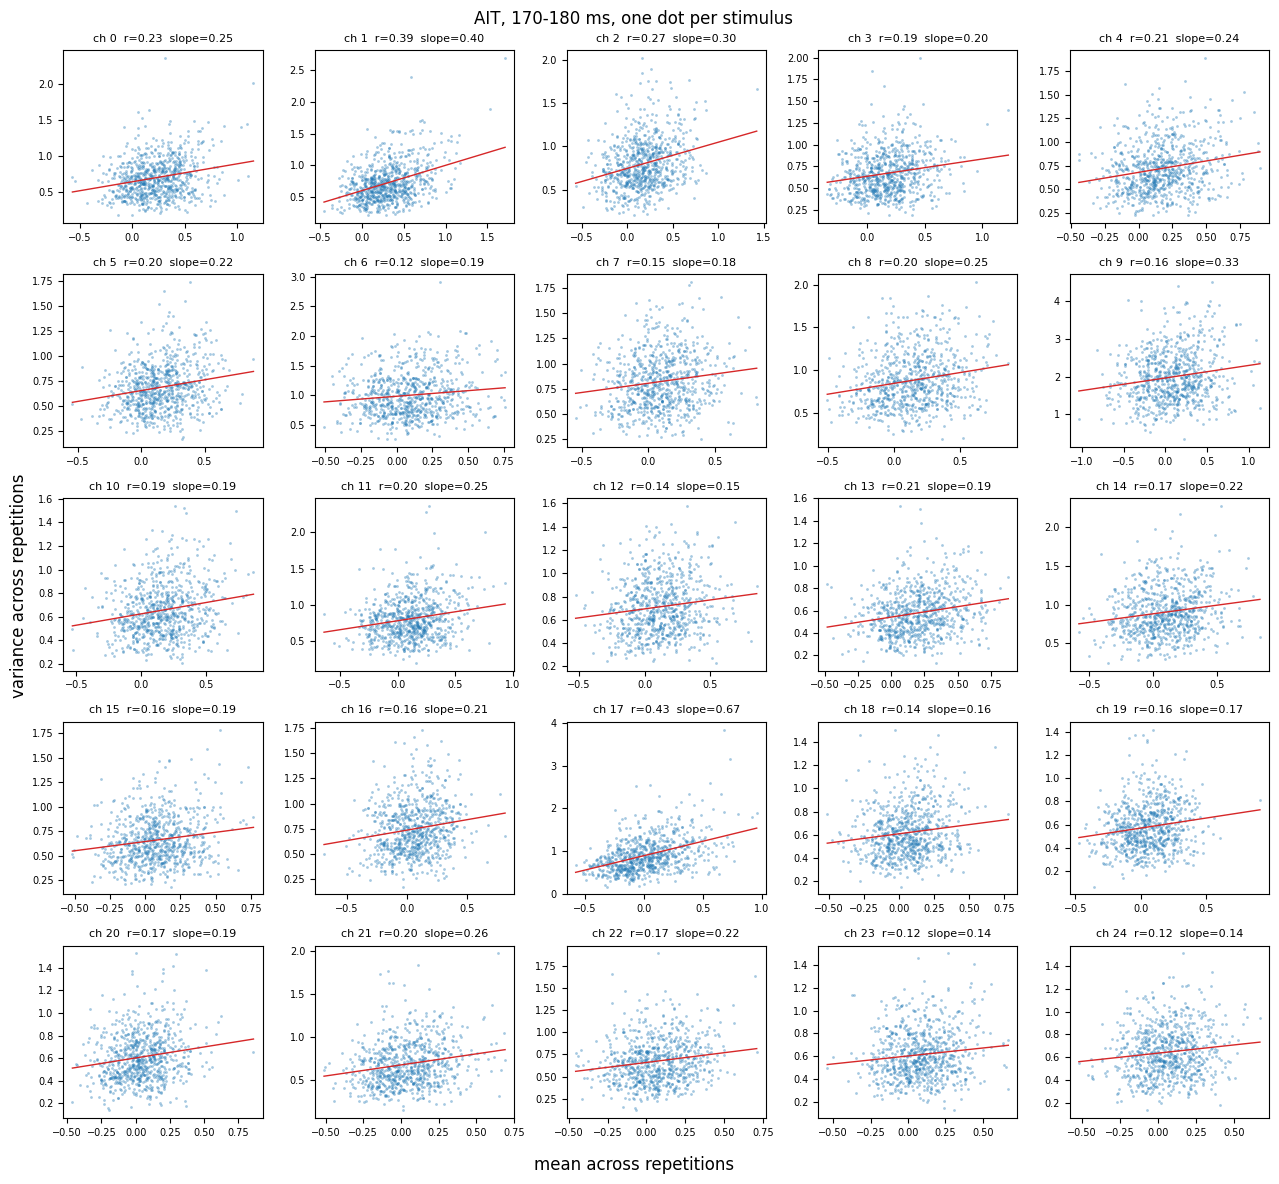

In [6]:
"""
plot_mean_variance
Scatter the across-repetition variance against the mean for every channel.

INPUT:
    - bin_index: int -> time bin to plot

OUTPUT:
    - fig: matplotlib.figure.Figure -> channel grid
"""
def plot_mean_variance(bin_index):
    n_cols = int(np.ceil(np.sqrt(n_neurons)))
    n_rows = int(np.ceil(n_neurons / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 2.4 * n_rows), squeeze=False)
    for channel, ax in enumerate(axes.flat):
        if channel >= n_neurons:
            ax.axis("off")
            continue
        # end if the grid cell has no channel
        means = image_mean[:, channel, bin_index]
        variances = image_var[:, channel, bin_index]
        valid = np.isfinite(variances)
        ax.scatter(means[valid], variances[valid], s=4, alpha=0.4, color="tab:blue", linewidths=0)
        # Linear trend and correlation summarise how noise scales with the mean.
        slope, intercept = np.polyfit(means[valid], variances[valid], 1)
        x_line = np.array([means[valid].min(), means[valid].max()])
        ax.plot(x_line, slope * x_line + intercept, color="tab:red", lw=1)
        r = np.corrcoef(means[valid], variances[valid])[0, 1]
        ax.set_title(f"ch {channel}  r={r:.2f}  slope={slope:.2f}", fontsize=8)
        ax.tick_params(labelsize=7)
    # end for channel
    fig.supxlabel("mean across repetitions")
    fig.supylabel("variance across repetitions")
    fig.suptitle(f"{cfg.brain_area}, {bin_starts_ms[bin_index]:.0f}-{bin_starts_ms[bin_index] + bin_width_ms:.0f} ms, one dot per stimulus")
    fig.tight_layout()
    return fig
# EOF


plot_mean_variance(timebin_index);

## 4. QQ plots of within-stimulus z-scores

Trials of all kept stimuli are pooled after within-stimulus z-scoring. The grey band is the 95% range of the same curve for Gaussian data with the same repetition counts; departures outside it are real. Reading guide: an **S-shape** (flat middle, steep ends) means heavy tails; the opposite means light tails or bimodality; a curve bent on **one side** means skew.

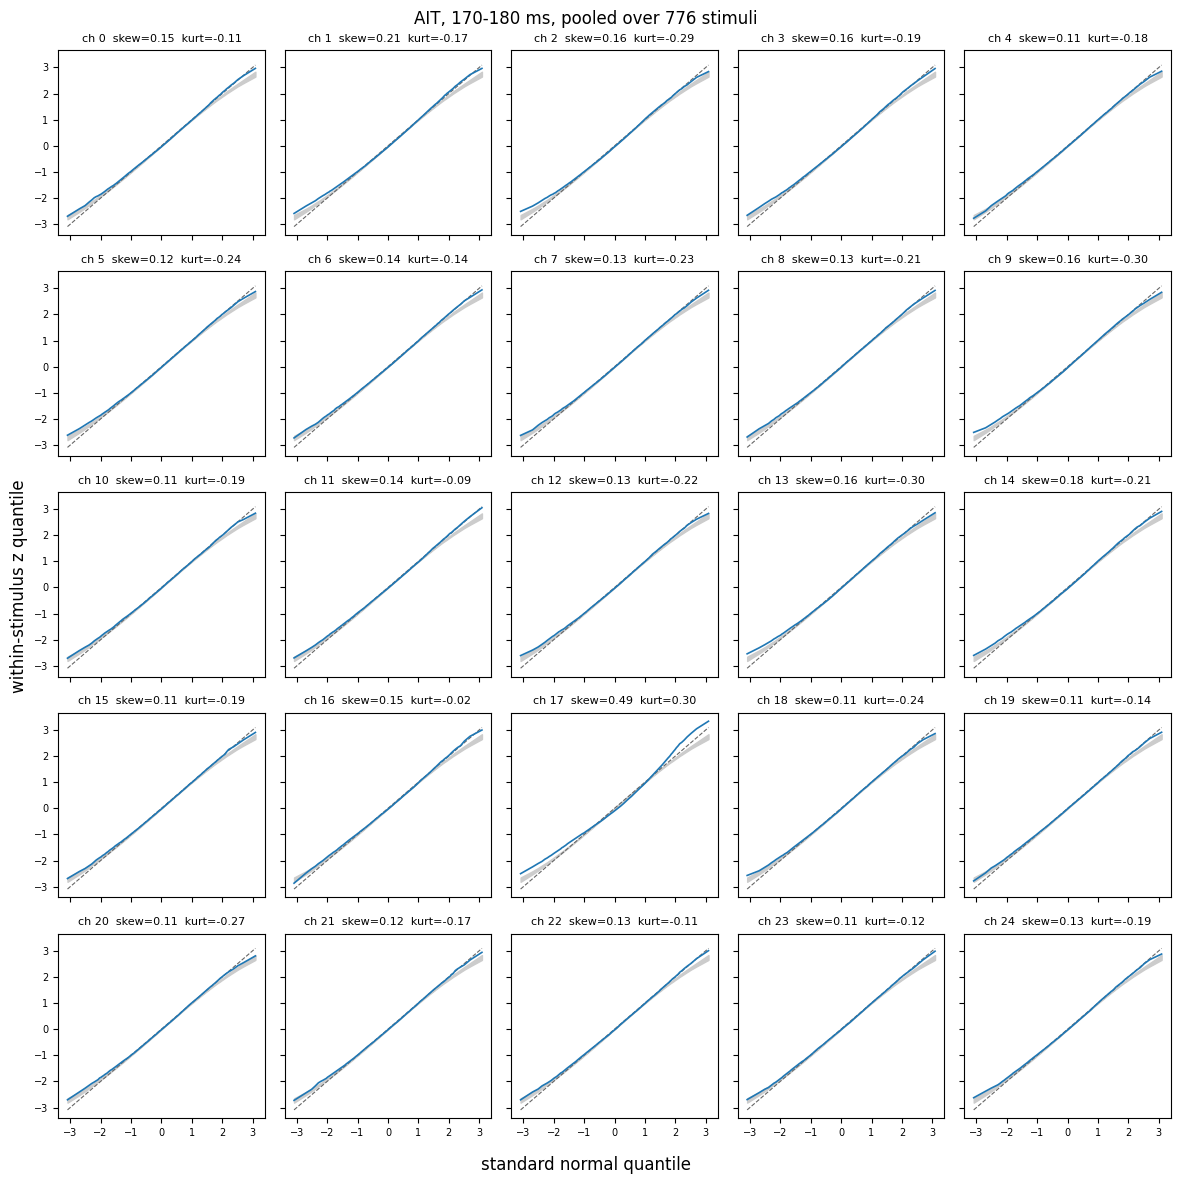

In [7]:
"""
plot_zscore_qq
QQ plot of the pooled within-stimulus z-scores for every channel, against the
standard normal and the matched-repetition Gaussian null.

INPUT:
    - bin_index: int -> time bin to plot

OUTPUT:
    - fig: matplotlib.figure.Figure -> channel grid
"""
def plot_zscore_qq(bin_index):
    n_cols = int(np.ceil(np.sqrt(n_neurons)))
    n_rows = int(np.ceil(n_neurons / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.4 * n_cols, 2.4 * n_rows), squeeze=False, sharex=True, sharey=True)
    for channel, ax in enumerate(axes.flat):
        if channel >= n_neurons:
            ax.axis("off")
            continue
        # end if the grid cell has no channel
        z = z_responses[channel, bin_index]
        z = z[np.isfinite(z)]
        empirical_quantiles = np.quantile(z, quantile_levels)
        ax.fill_between(normal_quantiles, *null_quantile_band, color="0.8", label="Gaussian null 95%")
        ax.plot(normal_quantiles, normal_quantiles, color="0.4", lw=0.8, ls="--")
        ax.plot(normal_quantiles, empirical_quantiles, color="tab:blue", lw=1.2)
        ax.set_title(f"ch {channel}  skew={stats.skew(z):.2f}  kurt={stats.kurtosis(z):.2f}", fontsize=8)
        ax.tick_params(labelsize=7)
    # end for channel
    fig.supxlabel("standard normal quantile")
    fig.supylabel("within-stimulus z quantile")
    fig.suptitle(f"{cfg.brain_area}, {bin_starts_ms[bin_index]:.0f}-{bin_starts_ms[bin_index] + bin_width_ms:.0f} ms, pooled over {n_kept} stimuli")
    fig.tight_layout()
    return fig
# EOF


plot_zscore_qq(timebin_index);

## 5. Skewness and excess kurtosis

Moments are computed **per stimulus** (across its repetitions) and then averaged over stimuli. This avoids a trap of the pooled z-scores: mixing stimuli whose noise levels differ inflates pooled kurtosis even when every stimulus is Gaussian. The heatmaps use a diverging scale centred on 0 (the Gaussian value); the dashed line marks the selected bin. The null band printed above applies to every cell.

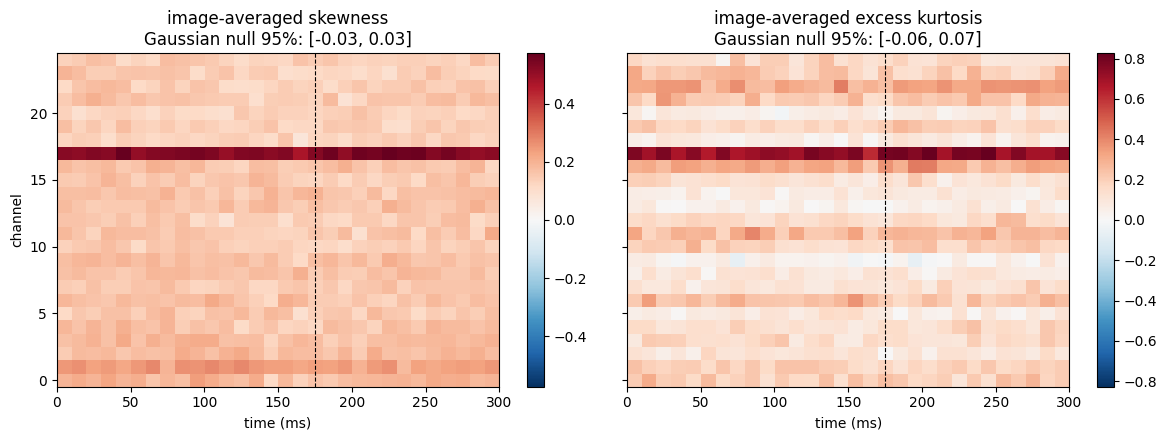

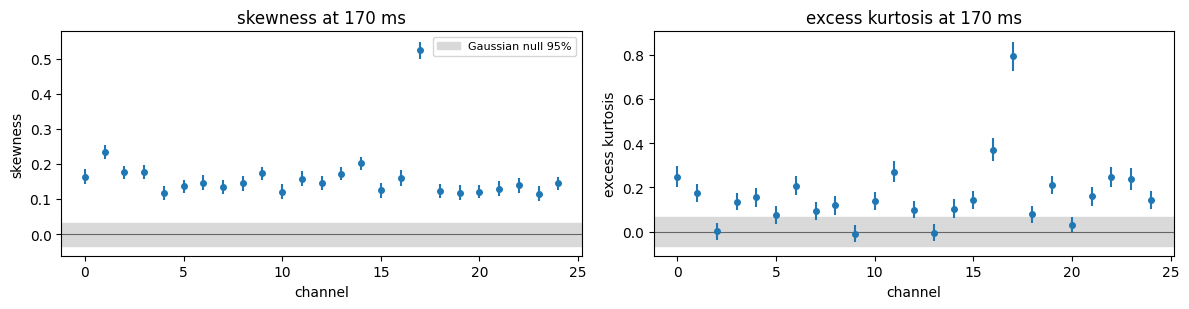

In [8]:
mean_skew = np.nanmean(image_skew, axis=0)  # [neurons, time]
mean_kurt = np.nanmean(image_kurt, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, values, label, band in zip(
    axes, [mean_skew, mean_kurt], ["skewness", "excess kurtosis"], [skew_band, kurt_band]
):
    limit = np.nanmax(np.abs(values))
    heatmap = ax.imshow(
        values, aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit, origin="lower",
        extent=[bin_starts_ms[0], bin_starts_ms[-1] + bin_width_ms, -0.5, n_neurons - 0.5],
    )
    ax.axvline(bin_centers_ms[timebin_index], color="k", ls="--", lw=0.8)
    ax.set_xlabel("time (ms)")
    ax.set_title(f"image-averaged {label}\nGaussian null 95%: [{band[0]:.2f}, {band[1]:.2f}]")
    fig.colorbar(heatmap, ax=ax)
# end for moment
axes[0].set_ylabel("channel")
fig.tight_layout()

# Channel-wise view at the selected bin, against the null band.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharex=True)
for ax, values, label, band in zip(
    axes, [mean_skew, mean_kurt], ["skewness", "excess kurtosis"], [skew_band, kurt_band]
):
    # Error bars: SEM across stimuli of the per-stimulus moment.
    per_image = image_skew if label == "skewness" else image_kurt
    sem = np.nanstd(per_image[:, :, timebin_index], axis=0) / np.sqrt(n_kept)
    ax.axhspan(*band, color="0.85", label="Gaussian null 95%")
    ax.errorbar(np.arange(n_neurons), values[:, timebin_index], yerr=sem, fmt="o", ms=4)
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set_xlabel("channel")
    ax.set_ylabel(label)
    ax.set_title(f"{label} at {bin_starts_ms[timebin_index]:.0f} ms")
# end for moment
axes[0].legend(fontsize=8)
fig.tight_layout()

## 6. One channel × stimulus across time

Top: every repetition of the target stimulus at every bin (dots), its distribution (violins) and mean. Bottom left: histogram at the selected bin with the moment-matched Gaussian. Bottom right: that stimulus' skewness and excess kurtosis over time, with the 95% range for Gaussian data with the same number of repetitions.

`target_stimulus` accepts an image name, an index into `image_names`, or `None` for the image with the strongest mean response on the target channel at the selected bin. The widget below lets you change channel, stimulus and bin interactively.

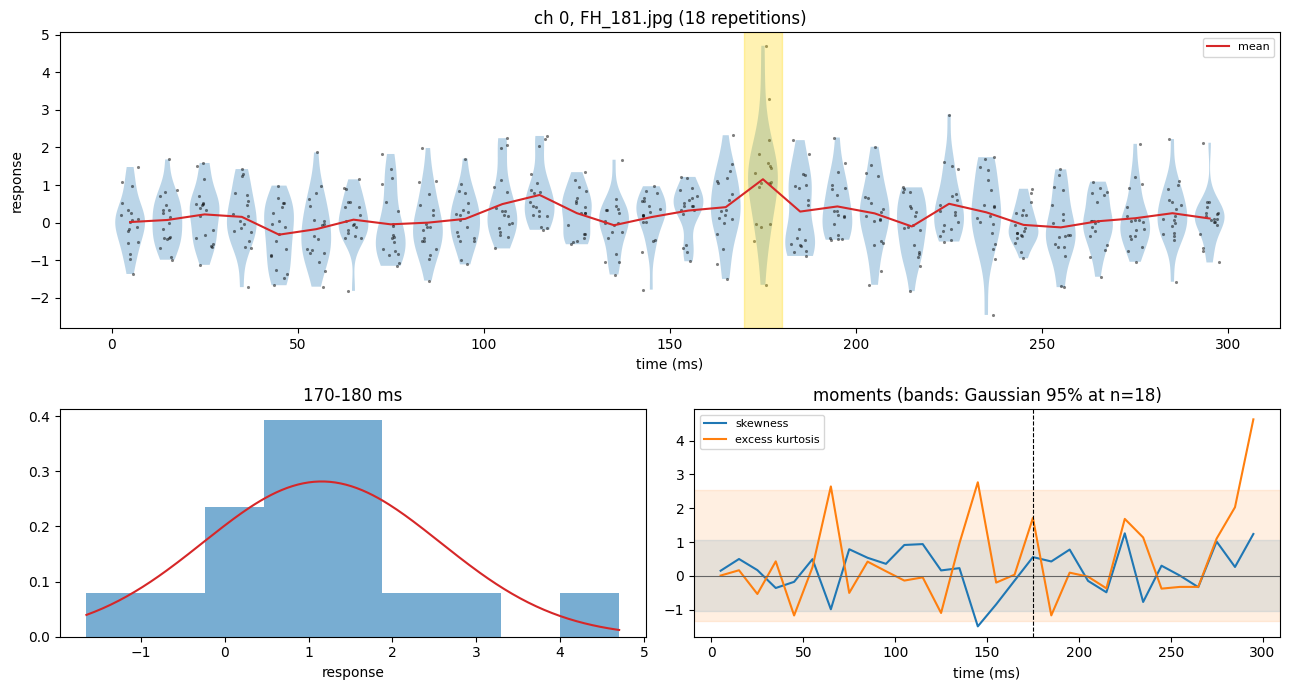

In [9]:
"""
resolve_stimulus
Turn a stimulus selector into the row of the per-image arrays and its name.

INPUT:
    - stimulus: str | int | None -> image name, index into image_names, or None
    - channel: int -> channel used to pick the strongest image when stimulus is None
    - bin_index: int -> bin used to pick the strongest image when stimulus is None

OUTPUT:
    - row: int -> row in image_mean / image_skew / image_kurt
    - image: int -> index into image_names
"""
def resolve_stimulus(stimulus, channel, bin_index):
    if stimulus is None:
        row = int(np.argmax(image_mean[:, channel, bin_index]))
        return row, int(keep_images[row])
    # end if no stimulus was chosen
    image = int(np.flatnonzero(image_names == stimulus)[0]) if isinstance(stimulus, str) else int(stimulus)
    if image not in keep_images:
        raise ValueError(f"{image_names[image]} has fewer than {cfg.min_repetitions} repetitions.")
    # end if the stimulus was dropped
    return int(np.flatnonzero(keep_images == image)[0]), image
# EOF


"""
plot_stimulus_over_time
Show the repetition-wise distribution of one channel's response to one
stimulus at every time bin, together with its moments.

INPUT:
    - channel: int -> local channel index within brain_area
    - stimulus: str | int | None -> see resolve_stimulus
    - bin_index: int -> time bin highlighted and histogrammed

OUTPUT:
    - fig: matplotlib.figure.Figure -> three-panel figure
"""
def plot_stimulus_over_time(channel=cfg.target_channel, stimulus=cfg.target_stimulus, bin_index=timebin_index):
    row, image = resolve_stimulus(stimulus, channel, bin_index)
    trials = responses[channel][:, trial_image == image].T  # [repetitions, time]
    n_reps = len(trials)

    # Single-stimulus Gaussian null for skewness and kurtosis at this n.
    null_sample = rng.standard_normal((5000, n_reps))
    single_skew_band = np.percentile(stats.skew(null_sample, axis=1, bias=False), [2.5, 97.5])
    single_kurt_band = np.percentile(stats.kurtosis(null_sample, axis=1, bias=False), [2.5, 97.5])

    fig = plt.figure(figsize=(13, 7))
    grid = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])
    ax_time = fig.add_subplot(grid[0, :])
    ax_hist = fig.add_subplot(grid[1, 0])
    ax_moment = fig.add_subplot(grid[1, 1])

    # Top: violins + jittered repetitions per bin.
    violins = ax_time.violinplot(trials, positions=bin_centers_ms, widths=0.8 * bin_width_ms, showextrema=False)
    for body in violins["bodies"]:
        body.set_alpha(0.3)
    # end for violin
    jitter = rng.uniform(-0.25, 0.25, trials.shape) * bin_width_ms
    ax_time.scatter((bin_centers_ms + jitter).ravel(), trials.ravel(), s=5, color="k", alpha=0.5, linewidths=0)
    ax_time.plot(bin_centers_ms, trials.mean(0), color="tab:red", lw=1.5, label="mean")
    ax_time.axvspan(bin_starts_ms[bin_index], bin_starts_ms[bin_index] + bin_width_ms, color="gold", alpha=0.3)
    ax_time.set_xlabel("time (ms)")
    ax_time.set_ylabel("response")
    ax_time.set_title(f"ch {channel}, {image_names[image]} ({n_reps} repetitions)")
    ax_time.legend(fontsize=8)

    # Bottom left: histogram at the selected bin with a moment-matched Gaussian.
    values = trials[:, bin_index]
    ax_hist.hist(values, bins=max(5, n_reps // 2), density=True, color="tab:blue", alpha=0.6)
    x_grid = np.linspace(values.min(), values.max(), 200)
    ax_hist.plot(x_grid, stats.norm.pdf(x_grid, values.mean(), values.std(ddof=1)), color="tab:red")
    ax_hist.set_xlabel("response")
    ax_hist.set_title(f"{bin_starts_ms[bin_index]:.0f}-{bin_starts_ms[bin_index] + bin_width_ms:.0f} ms")

    # Bottom right: moments over time vs the single-stimulus null.
    ax_moment.axhspan(*single_skew_band, color="tab:blue", alpha=0.12)
    ax_moment.axhspan(*single_kurt_band, color="tab:orange", alpha=0.12)
    ax_moment.plot(bin_centers_ms, image_skew[row, channel], color="tab:blue", label="skewness")
    ax_moment.plot(bin_centers_ms, image_kurt[row, channel], color="tab:orange", label="excess kurtosis")
    ax_moment.axhline(0, color="0.4", lw=0.8)
    ax_moment.axvline(bin_centers_ms[bin_index], color="k", ls="--", lw=0.8)
    ax_moment.set_xlabel("time (ms)")
    ax_moment.set_title(f"moments (bands: Gaussian 95% at n={n_reps})")
    ax_moment.legend(fontsize=8)
    fig.tight_layout()
    return fig
# EOF


plot_stimulus_over_time();

In [ ]:
# Interactive version: pick channel, stimulus and bin.
import ipywidgets as widgets

widgets.interact(
    lambda channel, stimulus, bin_index: plot_stimulus_over_time(channel, stimulus, bin_index) and None,
    channel=widgets.IntSlider(value=cfg.target_channel, min=0, max=n_neurons - 1),
    stimulus=widgets.Dropdown(options=[("strongest image", None)] + [(str(image_names[i]), str(image_names[i])) for i in keep_images]),
    bin_index=widgets.IntSlider(value=timebin_index, min=0, max=n_time - 1, description="bin"),
);

interactive(children=(IntSlider(value=0, description='channel', max=24), Dropdown(description='stimulus', opti…